# DOE-008
## トレーリング・ストップ ウィンドウ調査
- 対象銘柄: 9984
- EMA
    - PERIOD_MA_1 = 30
- トレーリング・ストップ利確
    - Start_TRAILING: トレーリング・ストップを開始する含み益
        - 20, 30, 40, 50, 60
    - THRESHOLD_TRAILING: トレーリング・ストップするしきい値
        - 0.3, 0.4, 0.5, 0.6, 0.7
- ロスカット
    - LOSSCUT_VWAP: VWAP 基準でロスカット
- クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
name_doe = "doe-008"
date_trade = "20260911"
name_code = "9984"
csv_file = f"../doe/{name_doe}/{date_trade}_{name_code}.csv"
print(csv_file)
df = pd.read_csv(csv_file)
pd.set_option("display.width", 120)
print(df)

../doe/doe-008/20260911_9984.csv
   TYPE_MA_1  PERIOD_MA_1  START_TRAILING  THRESHOLD_TRAILING  Profit  Transactions
0        EMA           30              20                 0.3   -15.0          36.0
1        EMA           30              30                 0.3   -74.0          36.0
2        EMA           30              40                 0.3   -88.0          36.0
3        EMA           30              50                 0.3   -88.0          36.0
4        EMA           30              60                 0.3   -88.0          36.0
5        EMA           30              20                 0.4   -32.0          36.0
6        EMA           30              30                 0.4   -94.0          36.0
7        EMA           30              40                 0.4  -112.0          36.0
8        EMA           30              50                 0.4  -112.0          36.0
9        EMA           30              60                 0.4  -112.0          36.0
10       EMA           30              20  

In [3]:
cols_param = ["START_TRAILING", "THRESHOLD_TRAILING"]
cols_response = ["Profit", "Transactions"]

In [4]:
def gen_chart(ax, df1, name_x, name_y):
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )

    ax.set(xlabel=name_x, ylabel=name_y)
    ax.grid(True)

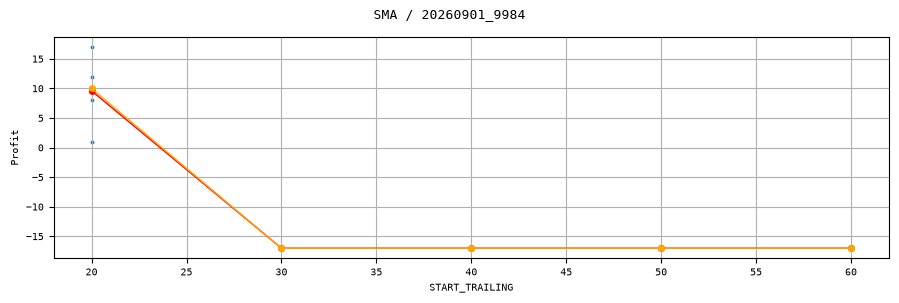

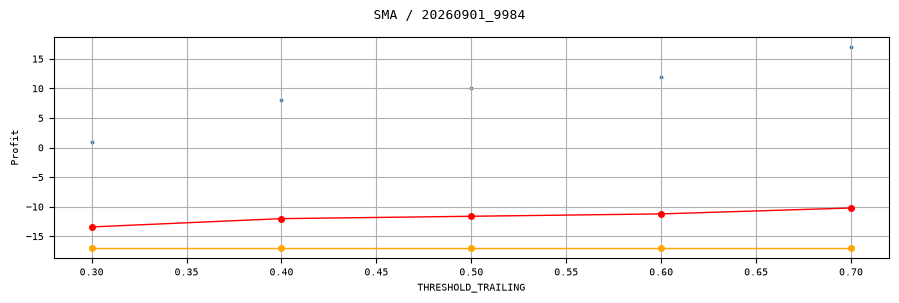

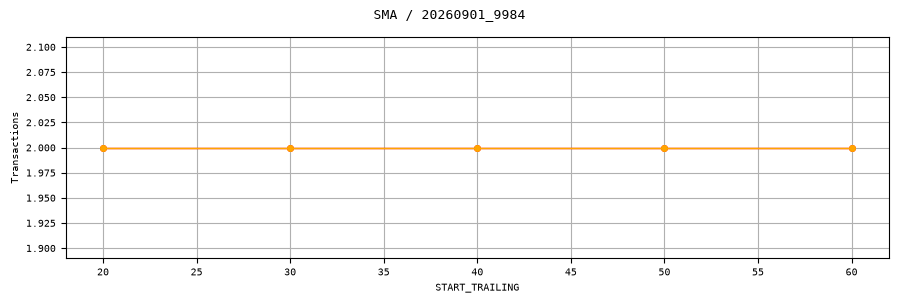

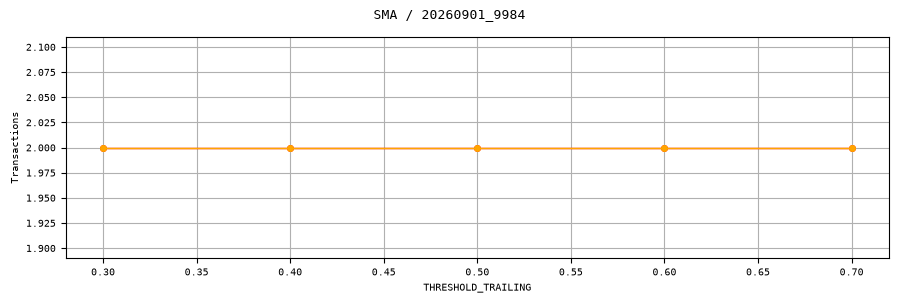

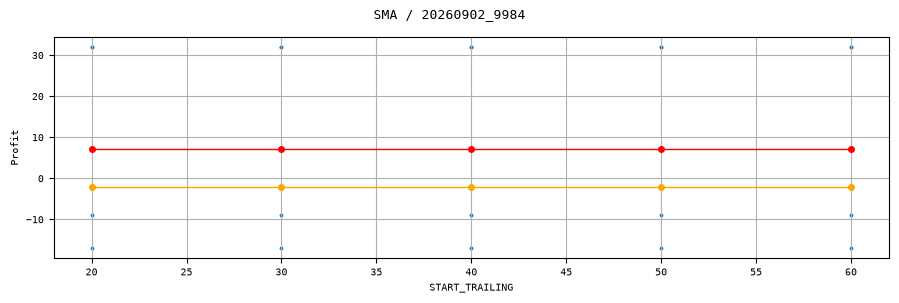

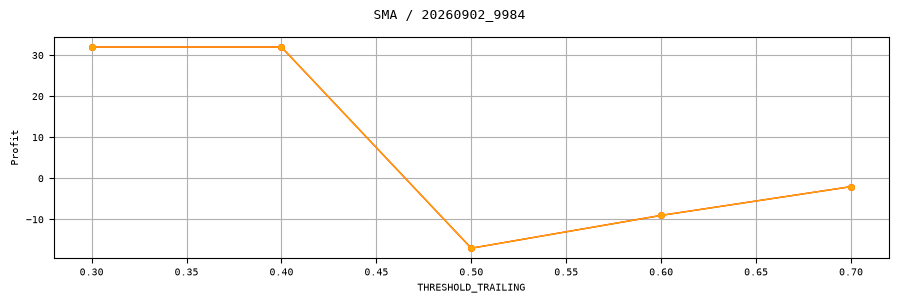

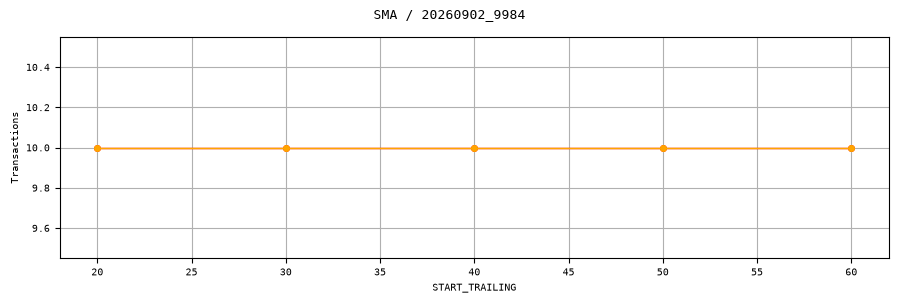

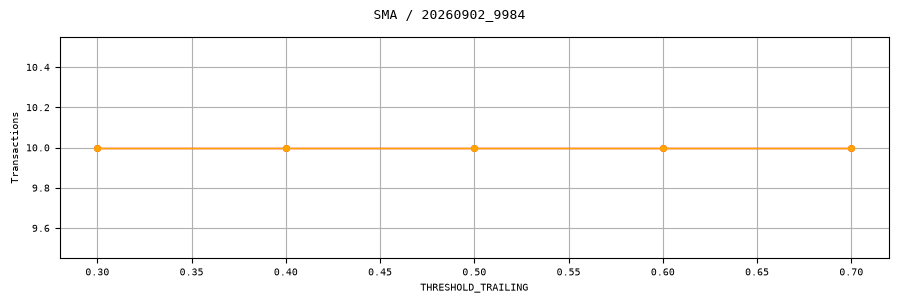

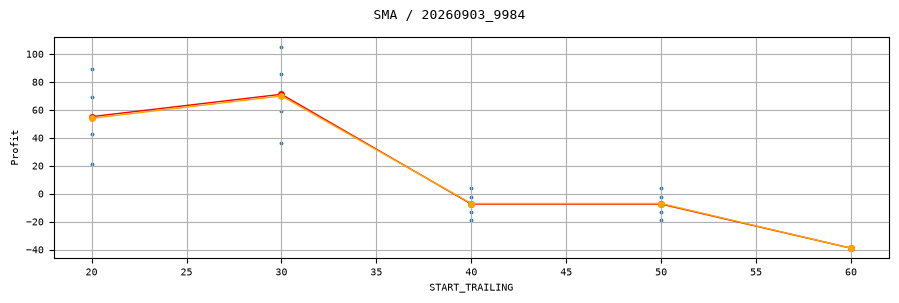

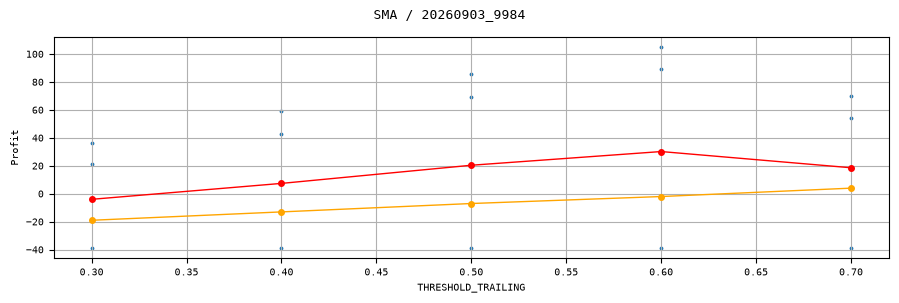

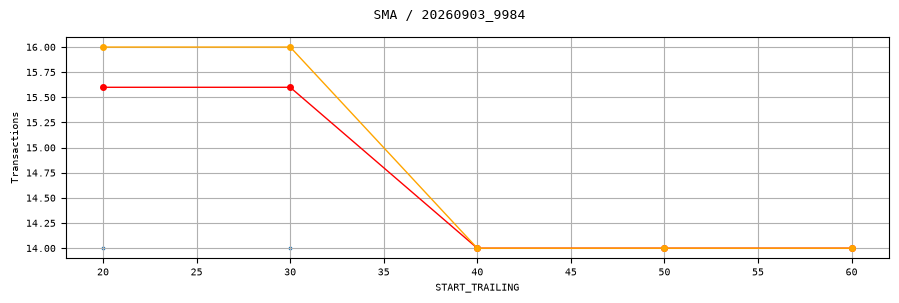

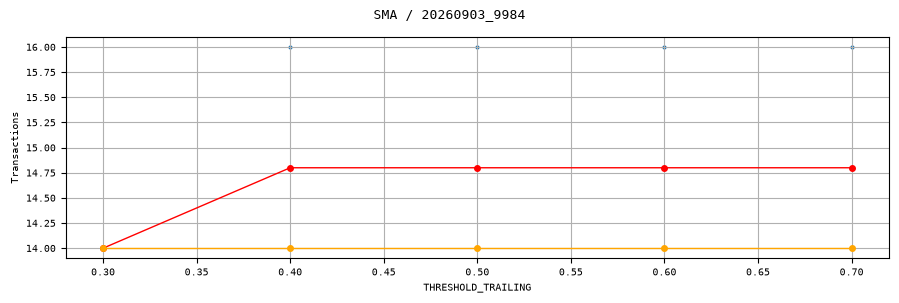

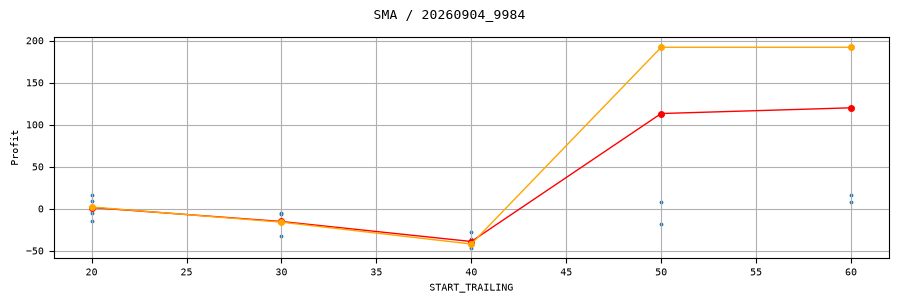

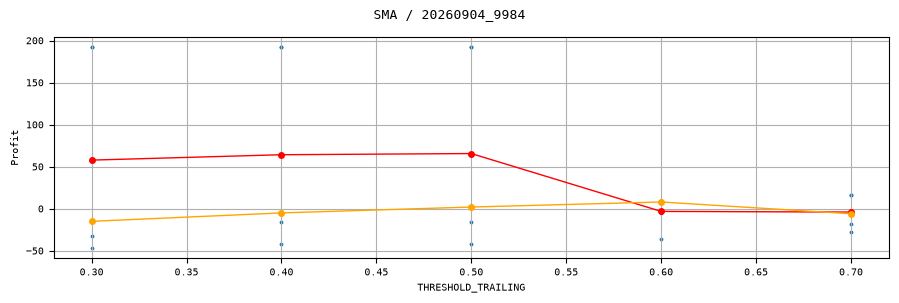

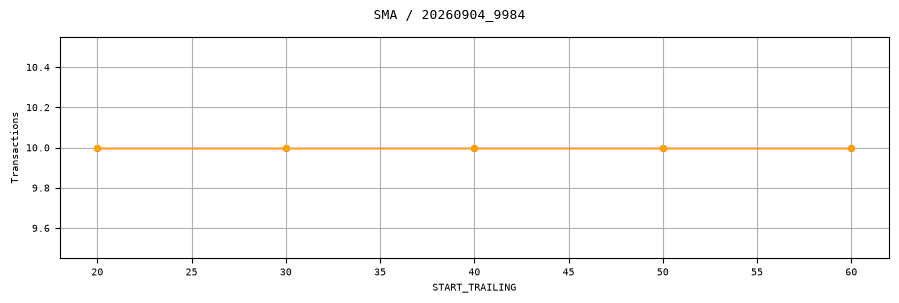

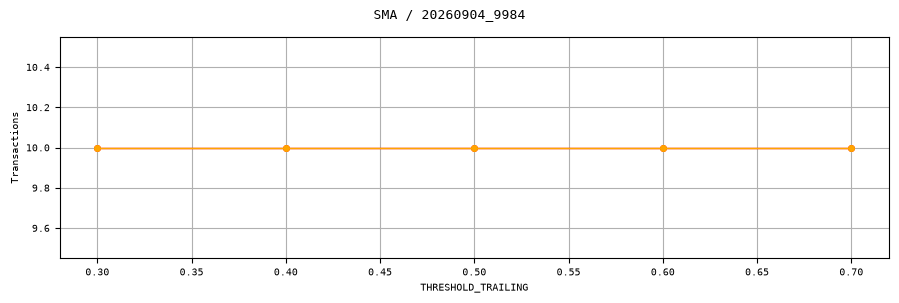

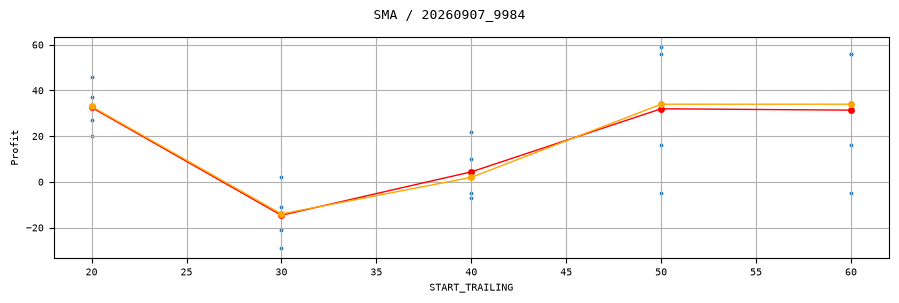

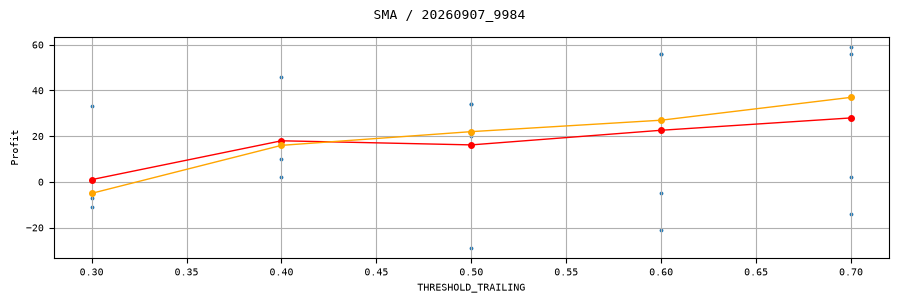

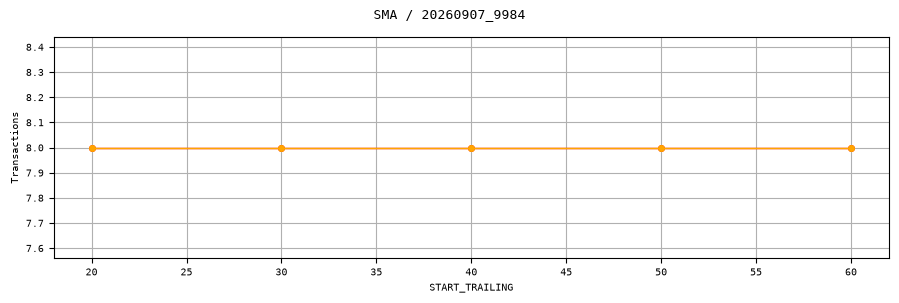

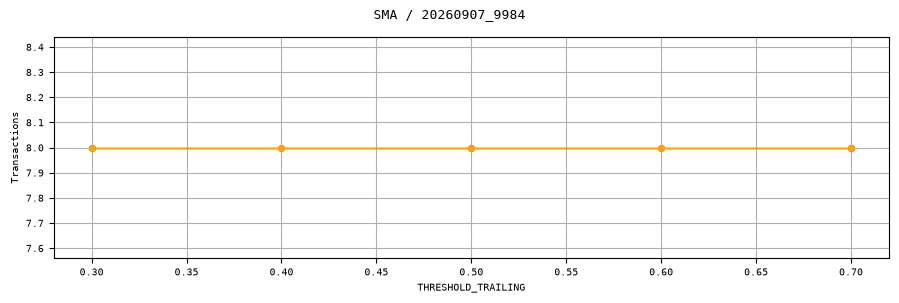

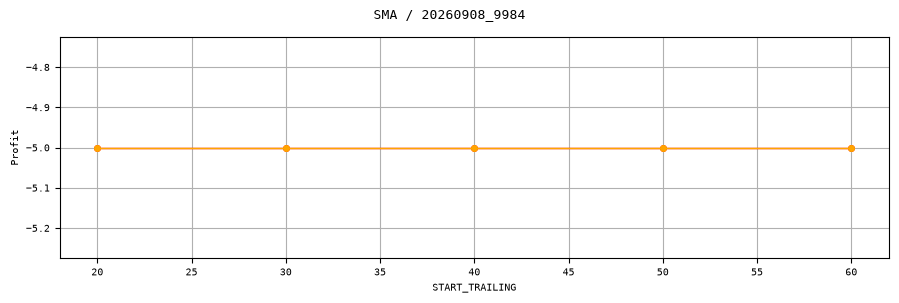

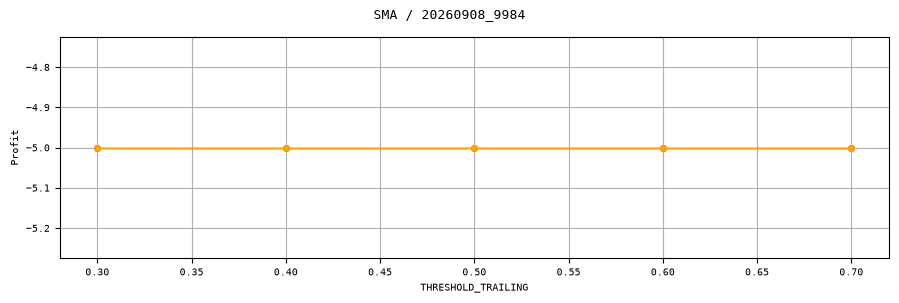

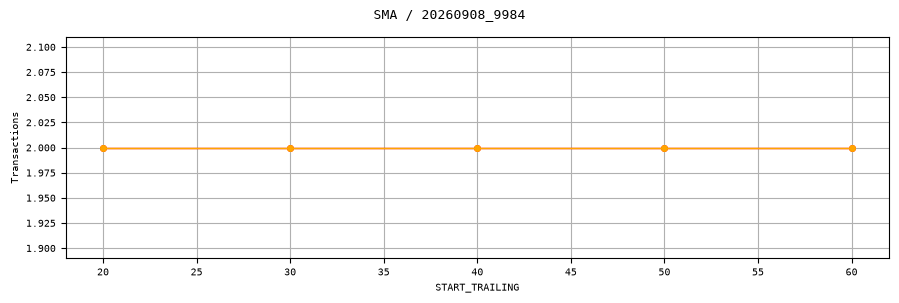

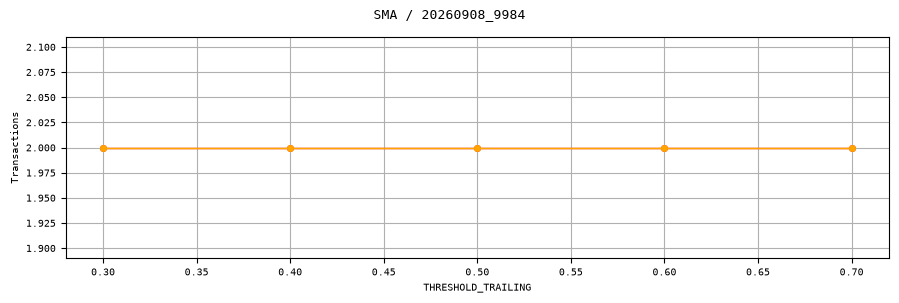

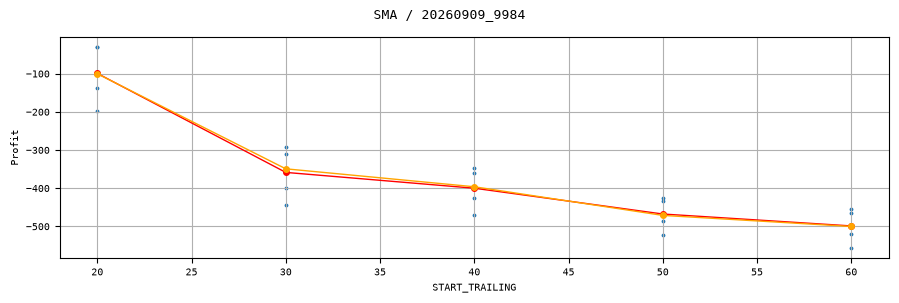

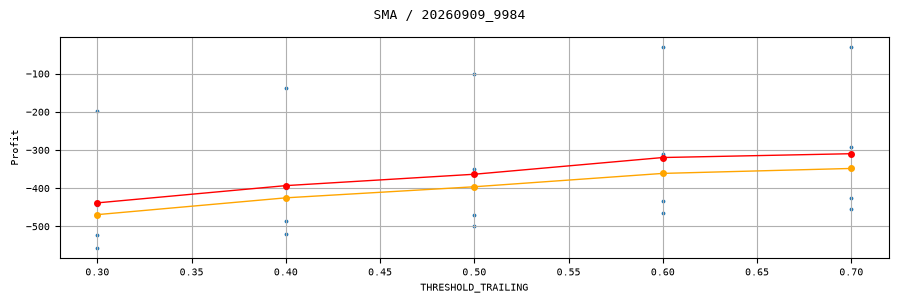

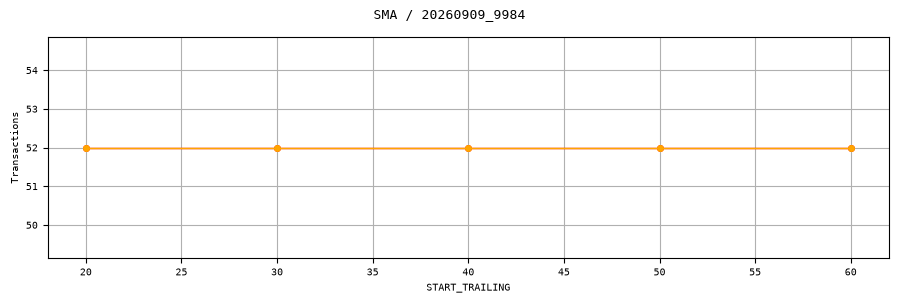

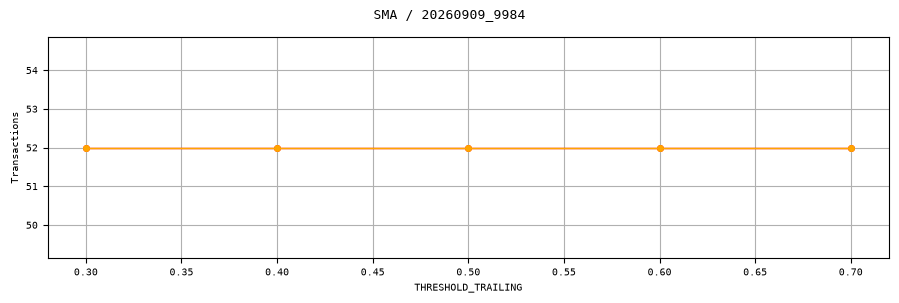

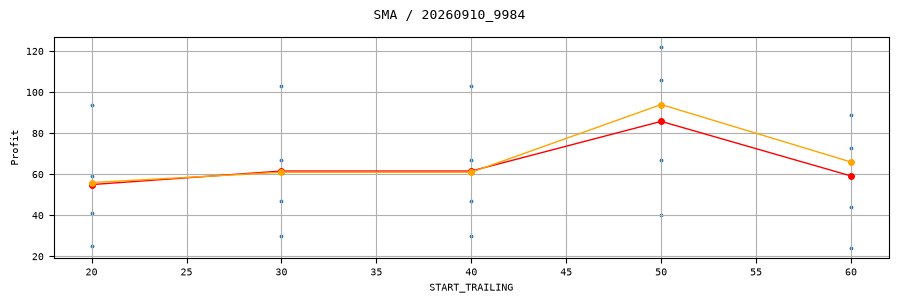

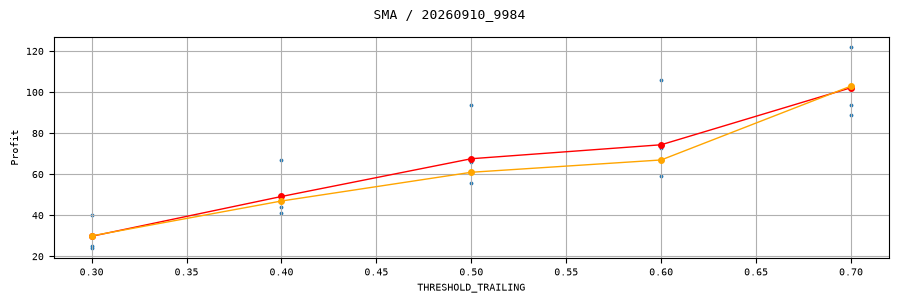

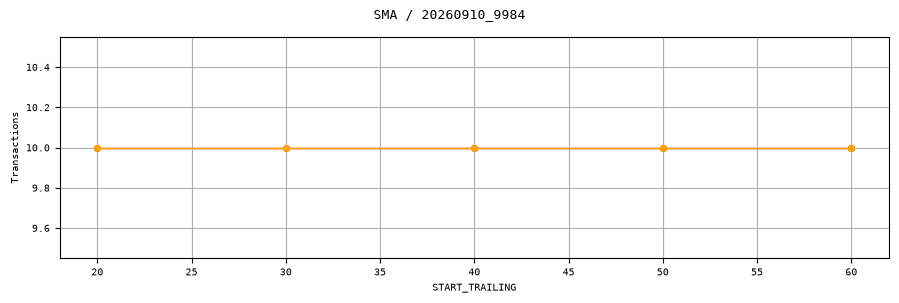

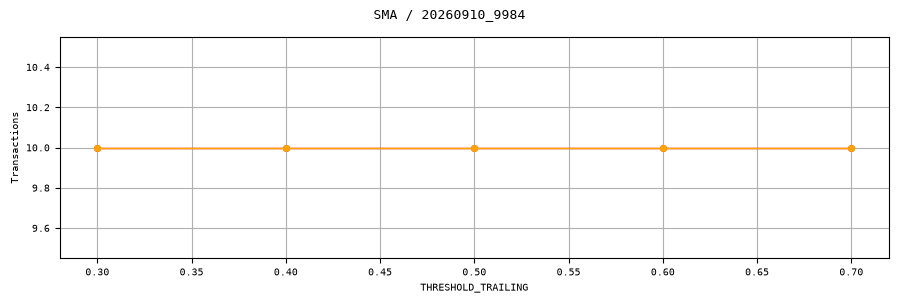

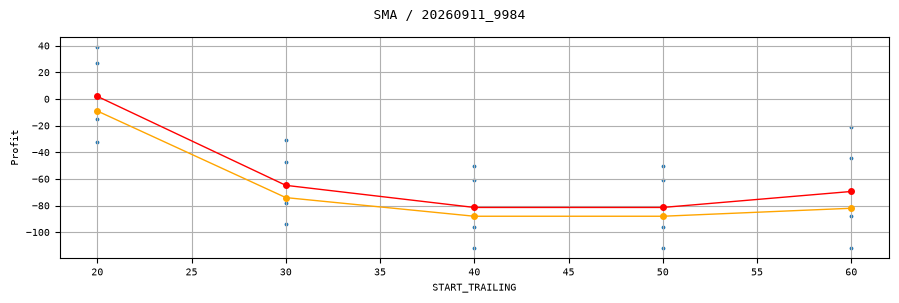

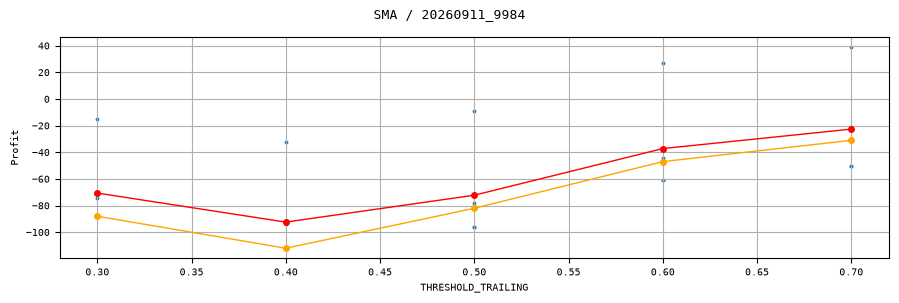

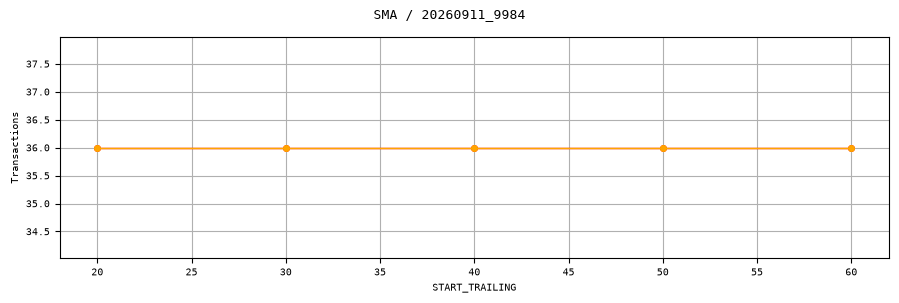

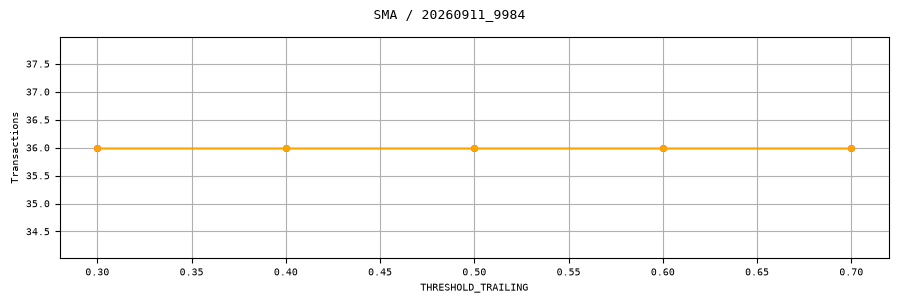

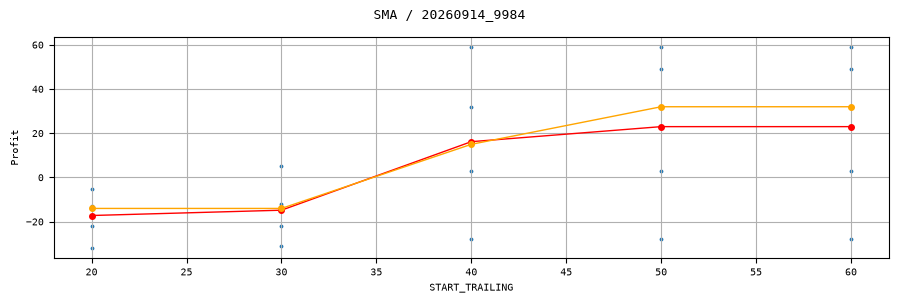

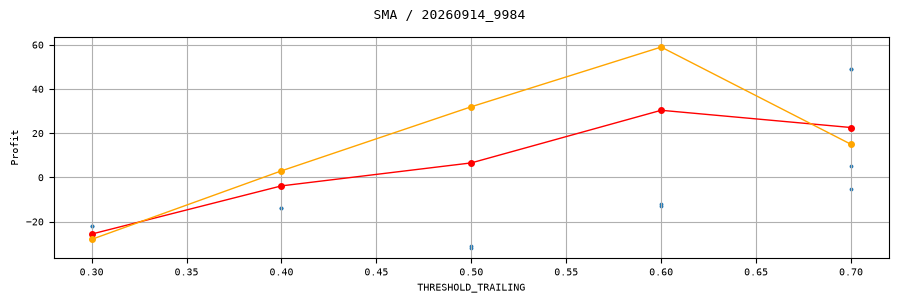

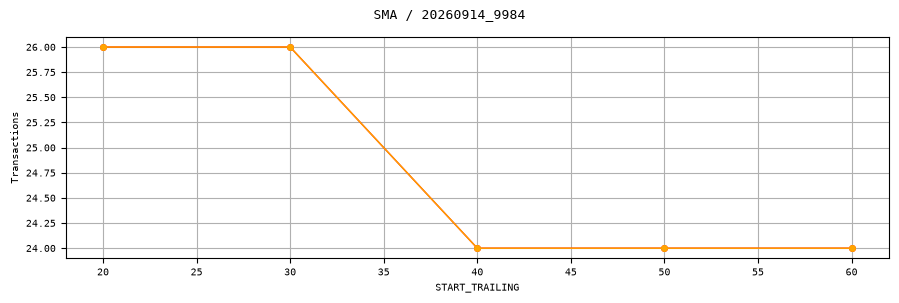

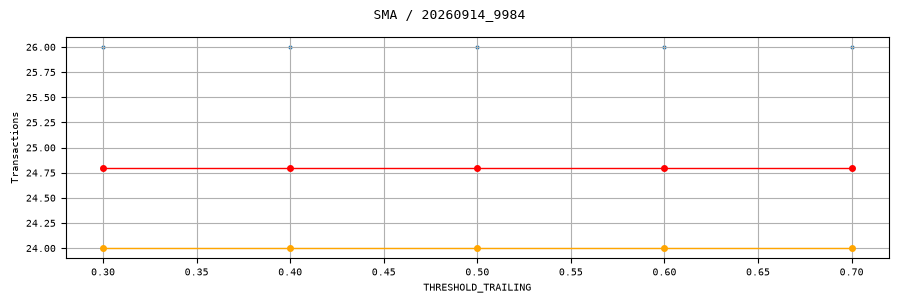

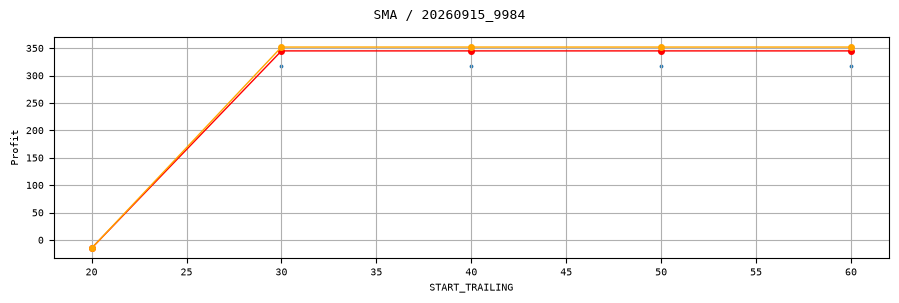

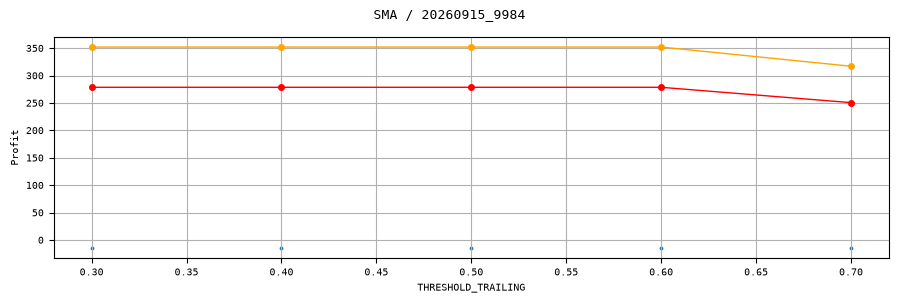

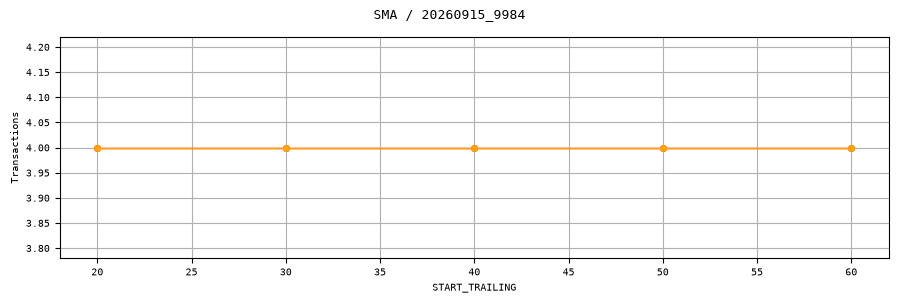

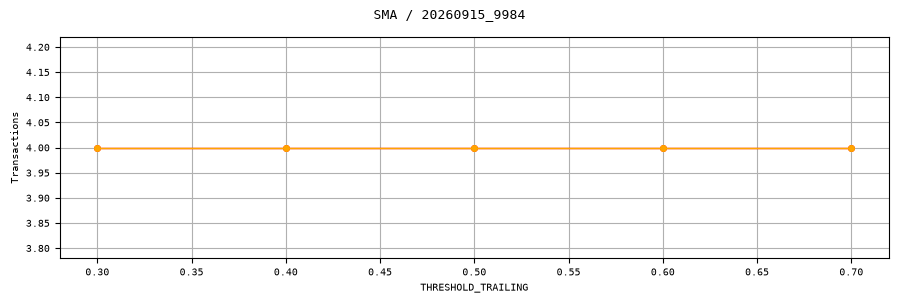

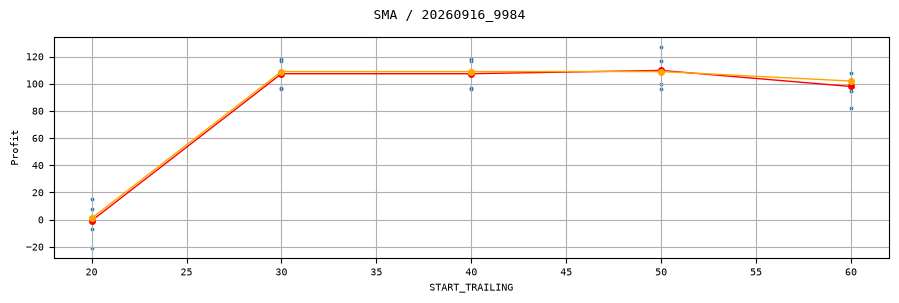

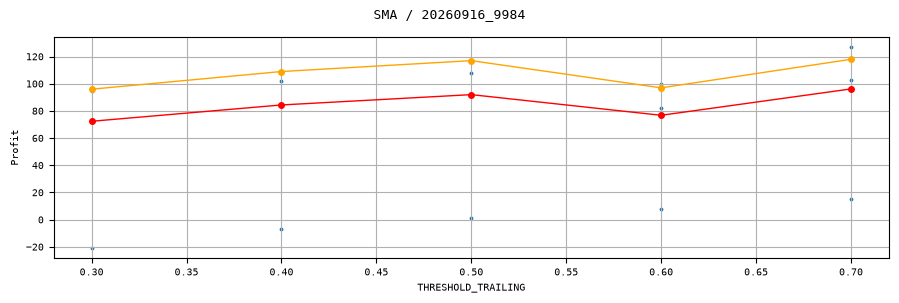

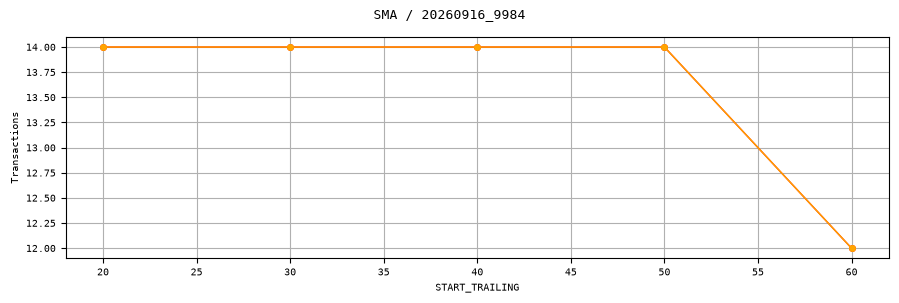

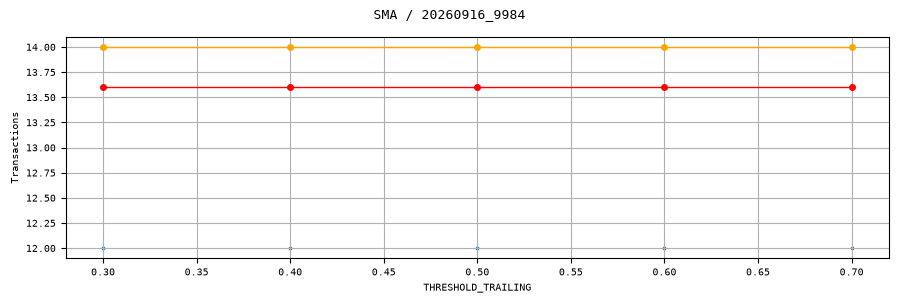

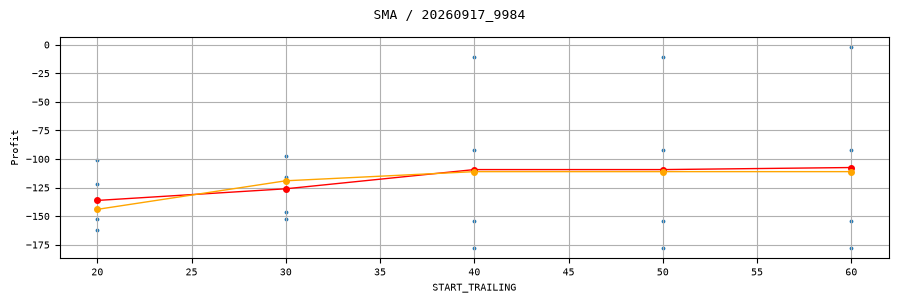

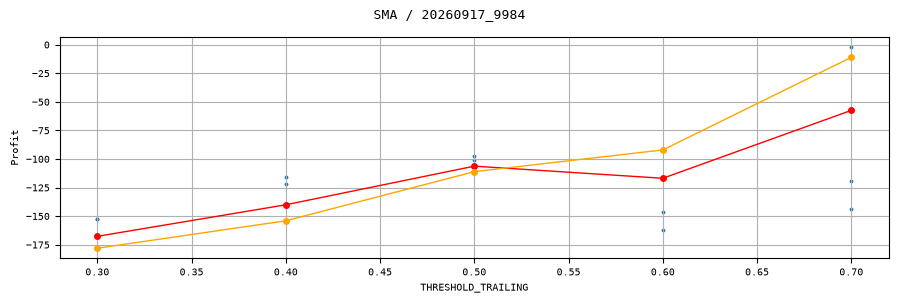

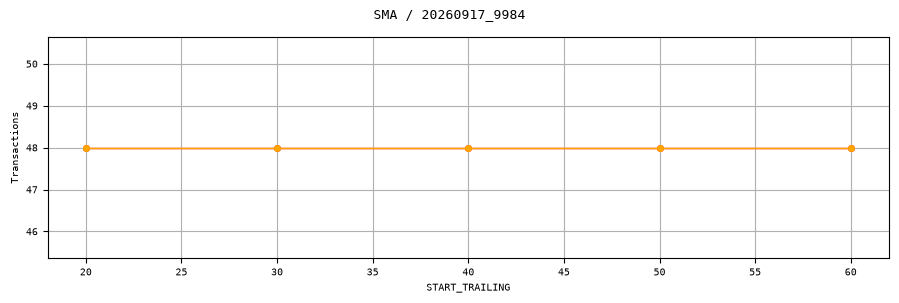

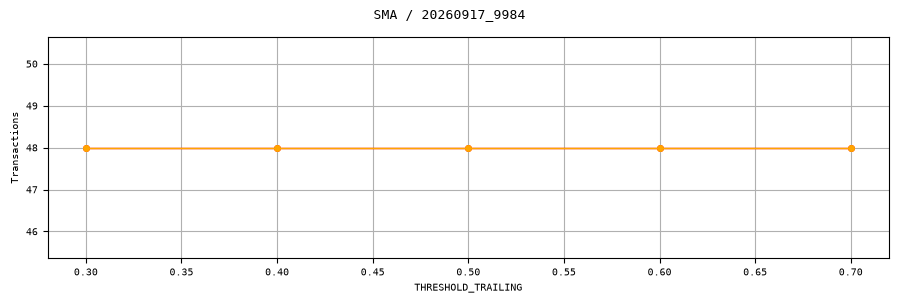

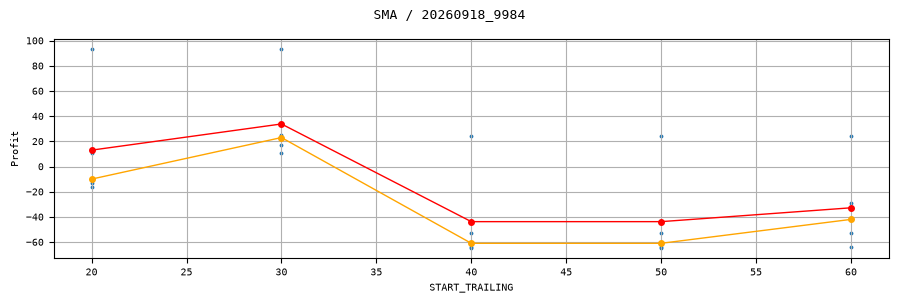

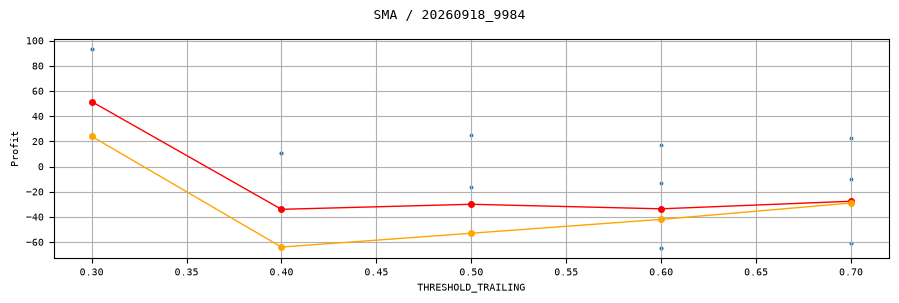

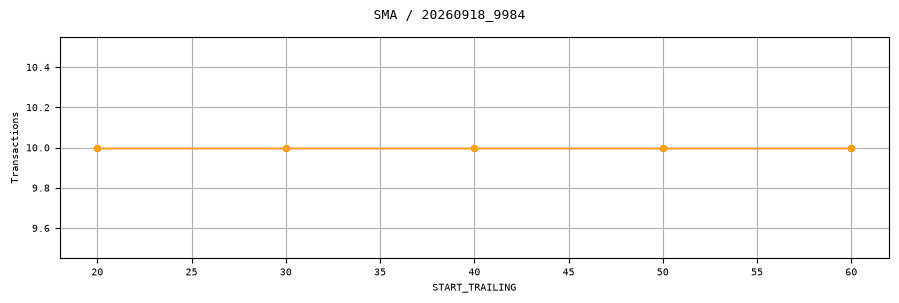

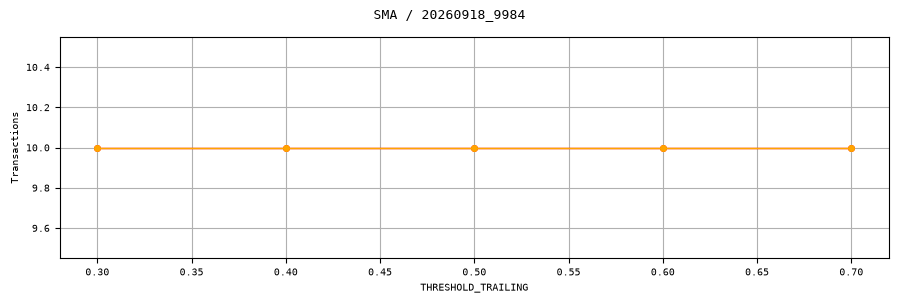

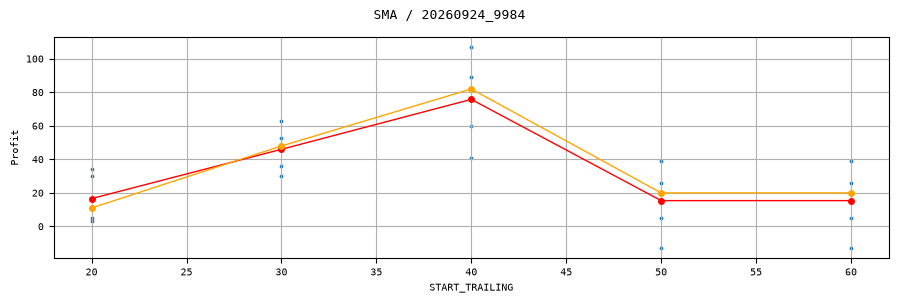

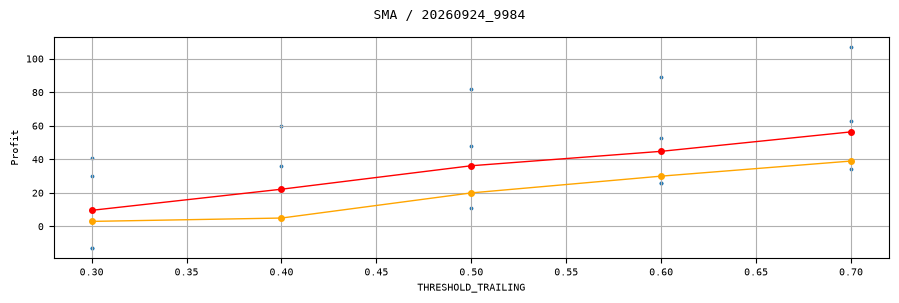

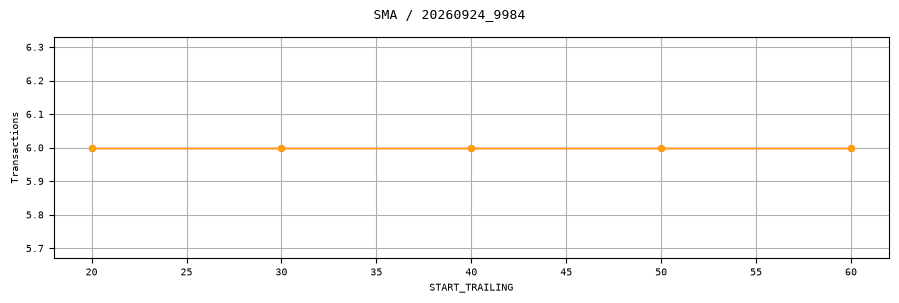

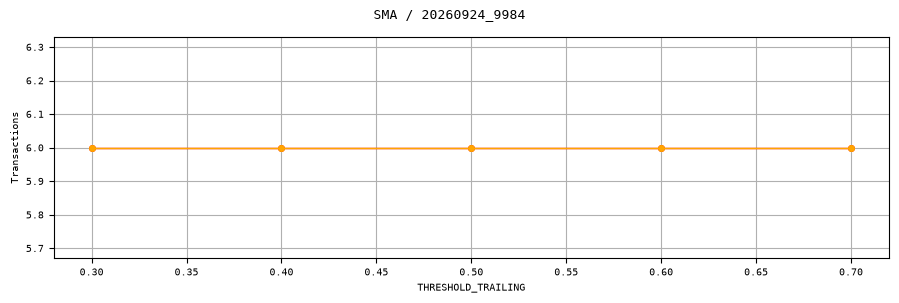

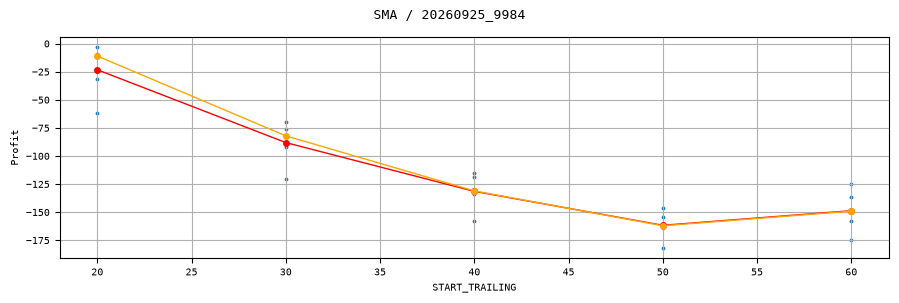

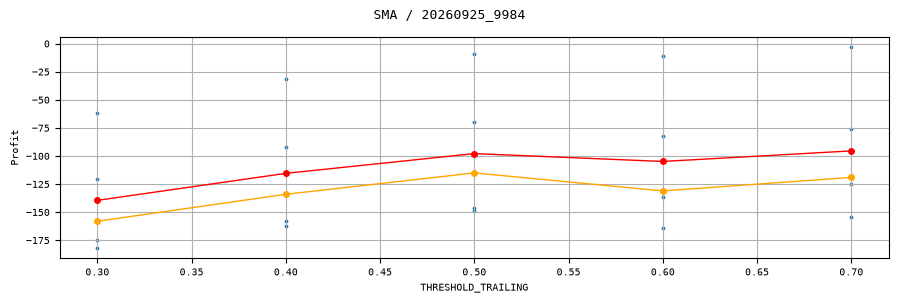

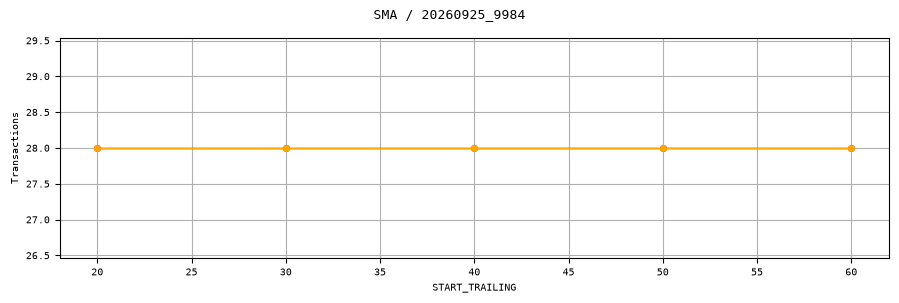

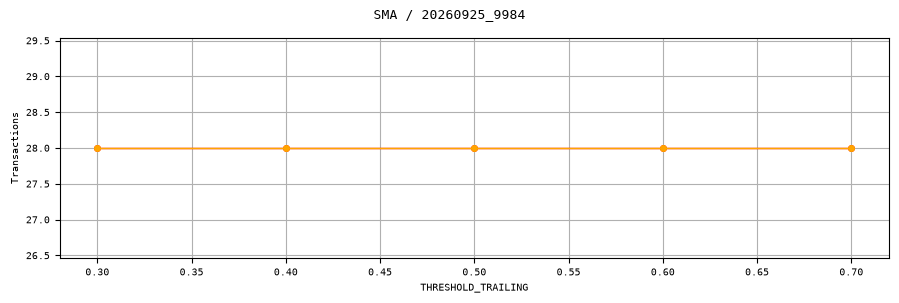

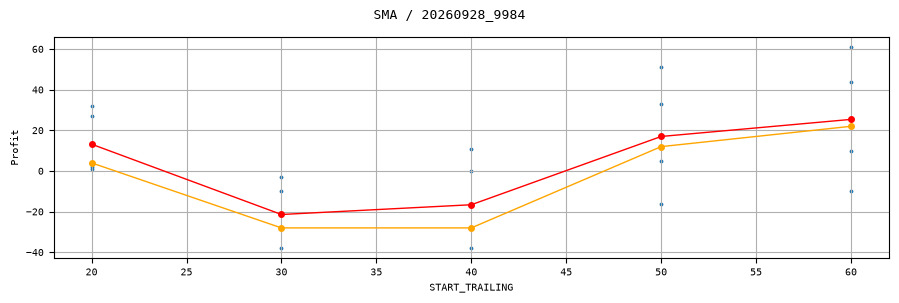

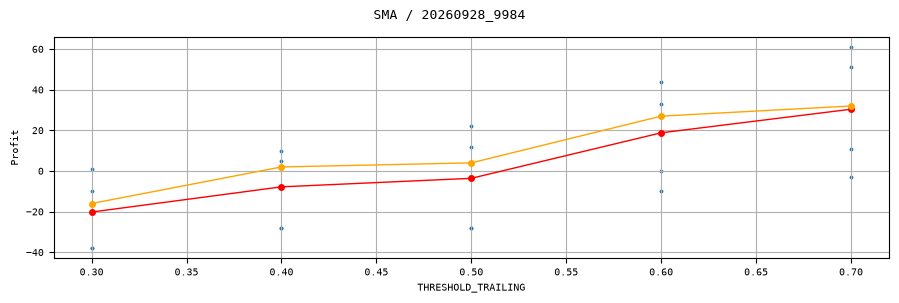

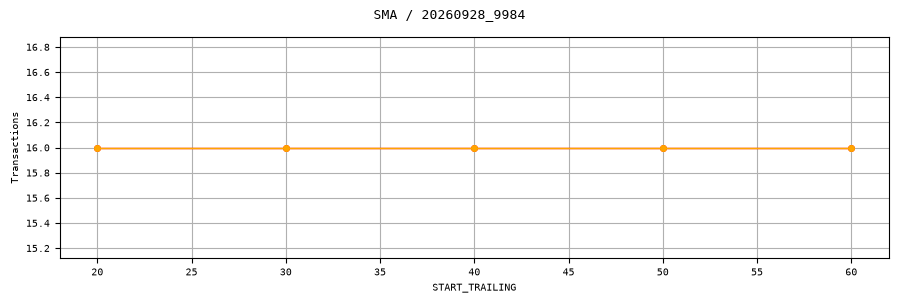

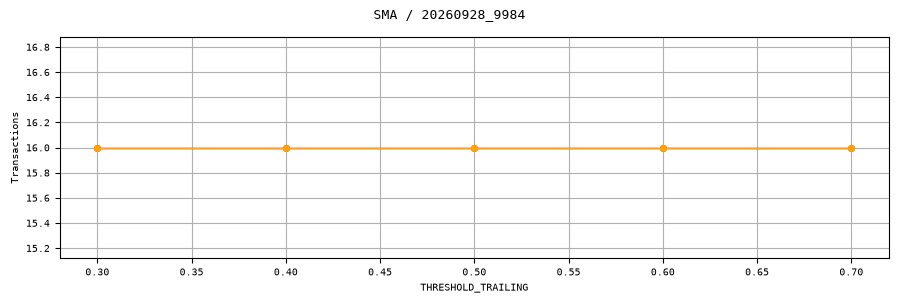

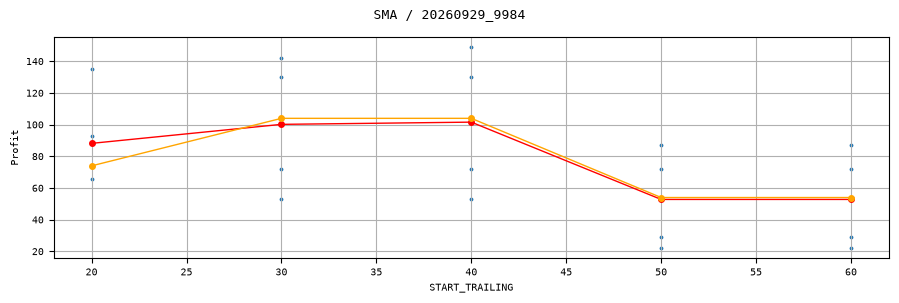

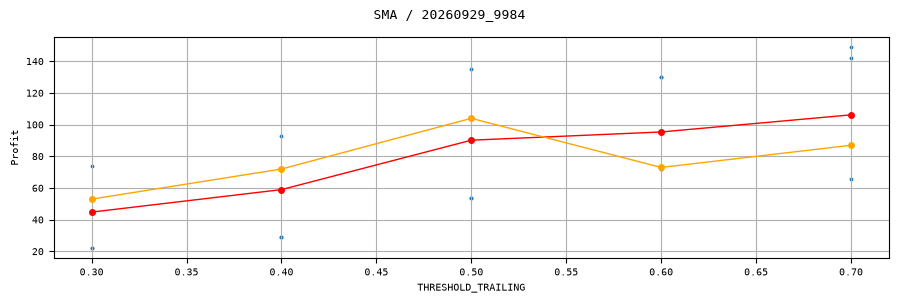

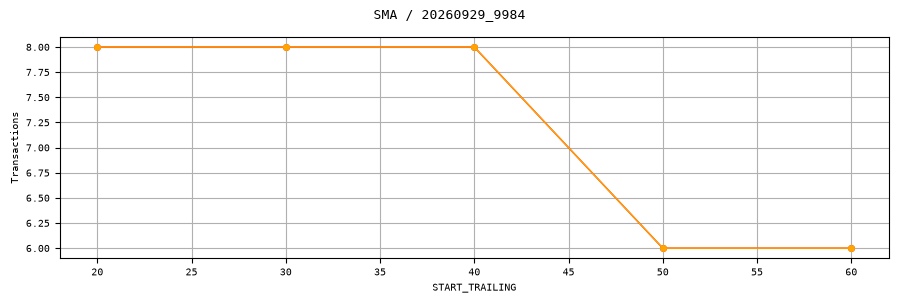

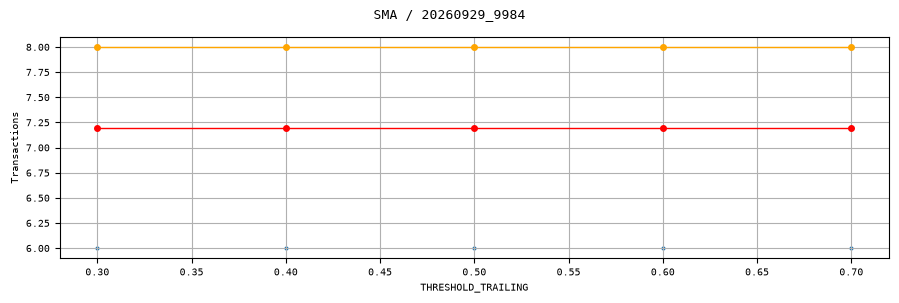

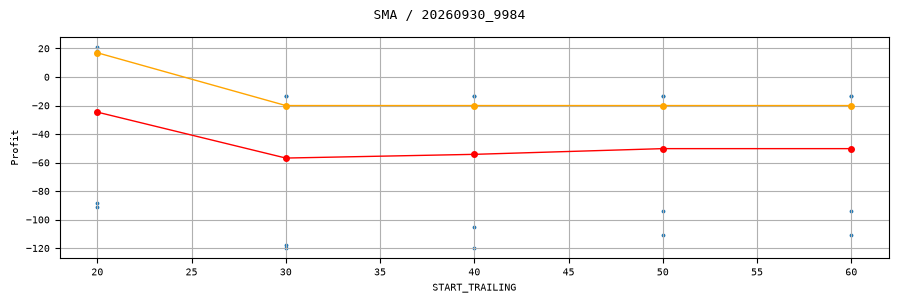

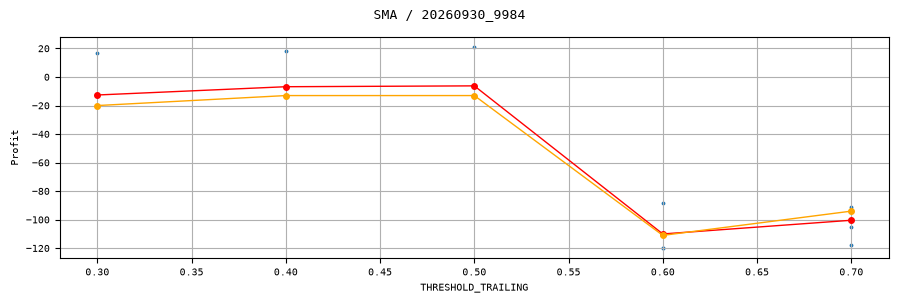

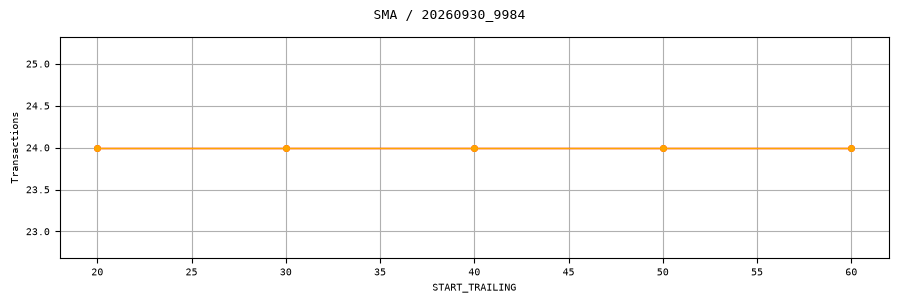

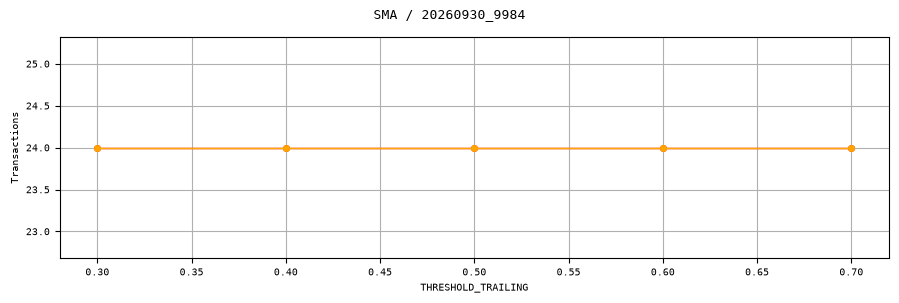

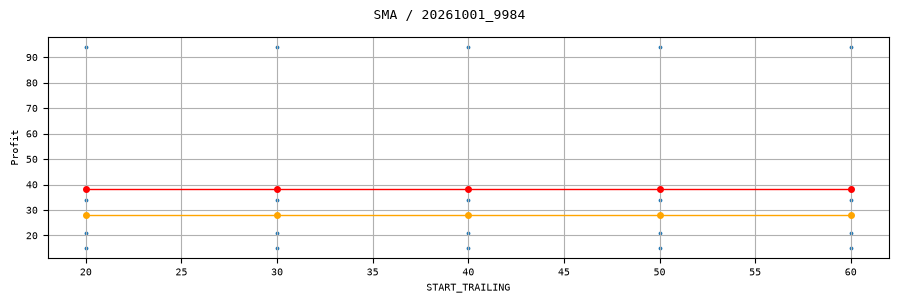

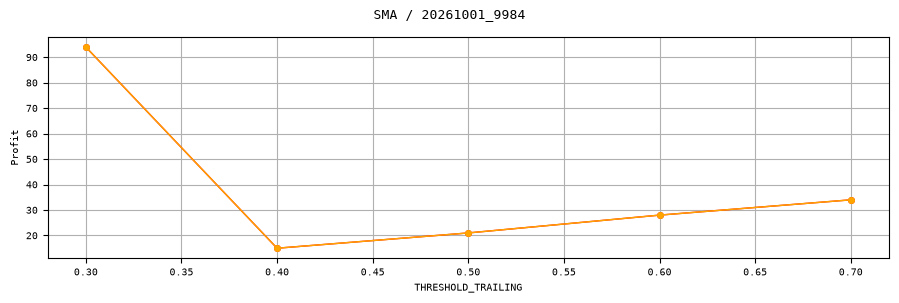

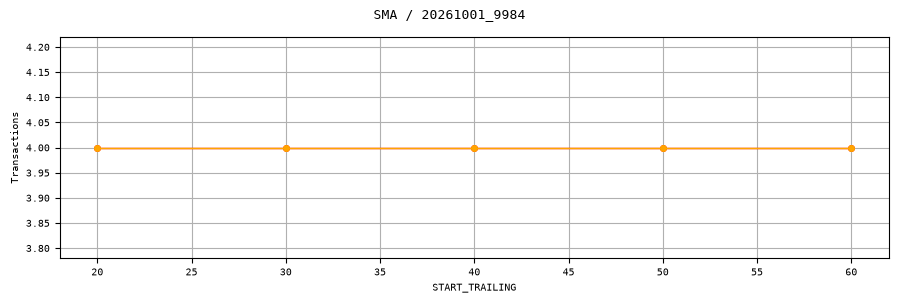

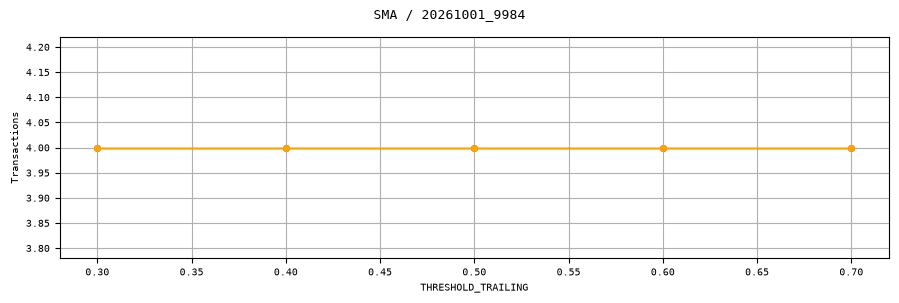

In [5]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7


# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

for csv_file in list_csv_file:
    df = pd.read_csv(csv_file)
    for name_y in cols_response:
        for name_x in cols_param:
            fig, ax = plt.subplots(1, 1, figsize=(9, 3))
            gen_chart(ax, df, name_x, name_y)

            basename = os.path.splitext(os.path.basename(csv_file))[0]
            date_trade, name_code = basename.split("_")
            fig.suptitle(f"SMA / {date_trade}_{name_code}", fontsize=9)

            plt.tight_layout()
            pngfile = (
                f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
            )
            plt.savefig(pngfile)
            plt.show()

In [6]:
import pandas as pd


# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "START_TRAILING",
    "THRESHOLD_TRAILING",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = (
    df.groupby(columns_group, as_index=False)
    .agg(
        Profit_Total=("Profit", "sum"),
        Profit_Median=("Profit", "median"),
    )
)

print(df_total)

   TYPE_MA_1  PERIOD_MA_1  START_TRAILING  THRESHOLD_TRAILING  Profit_Total  Profit_Median
0        EMA           30              20                 0.3        -110.0            1.0
1        EMA           30              20                 0.4         -54.0            3.5
2        EMA           30              20                 0.5          46.0            1.5
3        EMA           30              20                 0.6          42.0            8.5
4        EMA           30              20                 0.7         133.0           15.5
5        EMA           30              30                 0.3        -121.0           -8.0
6        EMA           30              30                 0.4         -58.0           -1.5
7        EMA           30              30                 0.5          64.0          -14.5
8        EMA           30              30                 0.6          66.0           -7.0
9        EMA           30              30                 0.7         193.0           -2.5